# Predicting User Churn at Waze: A Product Manager's Case Study

**Author:** Danish Khan · **Data:** practice Waze dataset from Google's Advanced Data Analytics Certificate ( ~15,000 users, one month of activity)

This notebook treats churn prediction as a **product decision**, not just a modeling exercise. It answers four questions:

1. **Who churns?** Which behaviors and user segments are linked to churn.
2. **Can we spot them early?** How well a model identifies at-risk users, and whether it beats a simple rule.
3. **Is it worth acting on?** What it costs to catch more churners, and where the threshold should sit.
4. **What should we do?** Interventions per segment, and an experiment plan to prove they work.

> **TL;DR:**
• Dataset: 14,299 labeled Waze users, 17.7% churned in the month.

• Strongest signal: driving frequency. Users who never drove churned at 40%, vs 5% for users who drove 20+ days.

• Heaviest drivers (top 10% by km per driving day) churned at 37%, 2.1x the average.

• Riskiest segment: Dormant (40% churn). Largest share of churners: Occasional long-haul (36% of all churners).

• Best model: XGBoost, PR-AUC 0.38 vs 0.32 for a simple rule and 0.18 for random guessing.

• On unseen users it catches 72% of churners by nudging 39% of users (2.1 unneeded nudges per churner caught).

• An A/B test needs about 3,162 flagged users per arm to detect a 10% relative drop in churn.


## 1. Problem framing

**Background.** Waze is a crowd-sourced product: every active driver both uses the map and improves it with real-time traffic and hazard reports. Churn therefore hurts twice: we lose the user, and the product gets slightly worse for everyone who stays.

**Problem.** A meaningful share of users stop using the app each month, and today we can't tell who is about to leave until they're gone.

**Goal.** Flag users who are likely to churn early enough for the retention team to act, and learn which behaviors signal churn so we can fix root causes, not just send reminders.

| | |
|---|---|
| **Primary users of this work** | Retention / growth PM, lifecycle marketing |
| **Success criteria** | Catch at least **70% of churners** (recall), at a precision where the intervention still pays for itself |
| **Key trade-off** | Missing a churner (false negative) costs more than nudging a loyal user (false positive), because a nudge is cheap and a lost user is not |
| **Non-goals** | Predicting the exact churn date; explaining *why* each individual leaves (that needs user research) |
| **Main constraint** | One month of aggregate behavior per user, no time series or survey data |

## 2. Setup

In [25]:
# !pip install pandas numpy matplotlib seaborn scipy scikit-learn xgboost statsmodels

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATA_PATH = "waze_dataset.csv"
CHART_DIR = Path("charts")          # LinkedIn-ready PNGs are saved here
CHART_DIR.mkdir(exist_ok=True)

# Product decisions, kept in one place so they're easy to debate and change
TARGET_RECALL = 0.70                 # catch at least 70% of churners

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)

In [26]:
# Chart style: one accent color carries the story, gray is context, titles state the takeaway
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#b5b4ae", "#e6e5e0", "#fcfcfb"
ACCENT = "#eb6834"      # churn / the thing to look at
BLUE, AQUA = "#2a78d6", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "font.size": 11, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def headline(ax, title, subtitle=None):
    # Title = the takeaway. Subtitle = what is actually plotted.
    ax.set_title(title)
    if subtitle:
        ax.text(0, 1.025, subtitle, transform=ax.transAxes, color=INK_2, fontsize=10.5, va="bottom")

def save(fig, name):
    fig.savefig(CHART_DIR / f"{name}.png")

def pct_axis(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(PercentFormatter(1.0, decimals=0))

## 3. The data

Each row is one user. Activity columns cover **one month**; `total_sessions`, the favorite-navigation counts and `n_days_after_onboarding` cover the user's lifetime.

| Column | Meaning |
|---|---|
| `label` | `retained` or `churned` (the target) |
| `sessions` / `drives` | App opens / drives of at least 1 km during the month |
| `total_sessions` | Estimated sessions since onboarding |
| `n_days_after_onboarding` | Tenure in days |
| `total_navigations_fav1/2` | Navigations to the user's top two saved places, since onboarding |
| `driven_km_drives` / `duration_minutes_drives` | Distance and time driven during the month |
| `activity_days` / `driving_days` | Days the user opened the app / drove at least 1 km during the month |
| `device` | iPhone or Android |

In [27]:
df_raw = pd.read_csv(DATA_PATH)
print(f"{df_raw.shape[0]:,} users, {df_raw.shape[1]} columns")
df_raw.head()

14,999 users, 13 columns


,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748,2276,208,0,"2,628.845","1,985.775",28,19,Android
1,1,retained,133,107,326.897,1225,19,64,"13,715.921","3,160.473",13,11,iPhone
2,2,retained,114,95,135.523,2651,0,0,"3,059.149","1,610.736",14,8,Android
3,3,retained,49,40,67.589,15,322,7,913.591,587.197,7,3,iPhone
4,4,retained,84,68,168.247,1562,166,5,"3,950.202","1,219.556",27,18,Android


In [28]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,"14,999.000","7,499.000","4,329.983",0.000,"3,749.500","7,499.000","11,248.500","14,998.000"
sessions,"14,999.000",80.634,80.699,0.000,23.000,56.000,112.000,743.000
drives,"14,999.000",67.281,65.914,0.000,20.000,48.000,93.000,596.000
total_sessions,"14,999.000",189.964,136.405,0.220,90.661,159.568,254.192,"1,216.155"
n_days_after_onboarding,"14,999.000","1,749.838","1,008.514",4.000,878.000,"1,741.000","2,623.500","3,500.000"
total_navigations_fav1,"14,999.000",121.606,148.122,0.000,9.000,71.000,178.000,"1,236.000"
total_navigations_fav2,"14,999.000",29.673,45.395,0.000,0.000,9.000,43.000,415.000
driven_km_drives,"14,999.000","4,039.341","2,502.149",60.441,"2,212.601","3,493.858","5,289.861","21,183.402"
duration_minutes_drives,"14,999.000","1,860.976","1,446.702",18.282,835.996,"1,478.250","2,464.363","15,851.727"
activity_days,"14,999.000",15.537,9.005,0.000,8.000,16.000,23.000,31.000


## 4. Data quality: can we trust what we're about to analyze?

### 4.1 Missing labels
Some users have no `label`, so they can't be used for training. Before dropping them, check they aren't a special group (for example, only new users or only Android). If their behavior looks like everyone else's, dropping them won't bias the results.

In [29]:
missing = df_raw["label"].isna()
print(f"{missing.sum():,} users ({missing.mean():.1%}) have no label\n")

num_cols = df_raw.select_dtypes("number").columns.drop("ID")
compare = pd.DataFrame({
    "median, label missing": df_raw.loc[missing, num_cols].median(),
    "median, label present": df_raw.loc[~missing, num_cols].median(),
})
compare["ratio"] = compare.iloc[:, 0] / compare.iloc[:, 1]
display(compare)

print("iPhone share | missing:", f"{(df_raw.loc[missing, 'device'] == 'iPhone').mean():.1%}",
      "| present:", f"{(df_raw.loc[~missing, 'device'] == 'iPhone').mean():.1%}")

700 users (4.7%) have no label



,"median, label missing","median, label present",ratio
sessions,56.000,56.000,1.000
drives,47.500,48.000,0.990
total_sessions,177.256,158.719,1.117
n_days_after_onboarding,"1,650.500","1,749.000",0.944
total_navigations_fav1,62.500,71.000,0.880
total_navigations_fav2,10.000,9.000,1.111
driven_km_drives,"3,421.157","3,496.546",0.978
duration_minutes_drives,"1,414.966","1,479.394",0.956
activity_days,15.000,16.000,0.938
driving_days,12.000,12.000,1.000


iPhone share | missing: 63.9% | present: 64.5%


**Read-out:** if the ratios sit close to 1 and the device mix matches, the missing labels look random and it's safe to drop those rows. If one group stands out, call it out as a limitation.

In [30]:
df = df_raw.dropna(subset=["label"]).copy()
df["churned"] = (df["label"] == "churned").astype(int)

BASELINE_CHURN = df["churned"].mean()
print(f"{len(df):,} labeled users | churn rate: {BASELINE_CHURN:.1%}")

14,299 labeled users | churn rate: 17.7%


### 4.2 Outliers and implausible values
Several usage columns have long right tails. Tree-based models handle these well; for logistic regression we'll cap values at the 95th percentile **learned from the training set only**, so nothing leaks from the test set.

We also sanity-check values that can't be real, such as more driving days than active days, or thousands of km in a single day. These are logging issues worth raising with the data-engineering team rather than silently deleting.

In [31]:
skewed = ["sessions", "drives", "total_sessions", "driven_km_drives", "duration_minutes_drives",
          "total_navigations_fav1", "total_navigations_fav2"]
display(df[skewed].quantile([0.5, 0.95, 0.99, 1.0]).T.rename(columns=lambda q: f"p{int(q*100)}"))

km_per_day = df["driven_km_drives"] / df["driving_days"].replace(0, np.nan)
checks = {
    "driving_days > activity_days": (df["driving_days"] > df["activity_days"]).sum(),
    "sessions > total_sessions": (df["sessions"] > df["total_sessions"]).sum(),
    "> 1,200 km per driving day (≈15h at highway speed)": (km_per_day > 1200).sum(),
}
for name, n in checks.items():
    print(f"{name:<52} {n:>6,} users ({n/len(df):.1%})")

,p50,p95,p99,p100
sessions,56.000,243.000,373.000,743.000
drives,48.000,200.000,306.020,596.000
total_sessions,158.719,455.439,643.594,"1,216.155"
driven_km_drives,"3,496.546","8,898.716","12,283.036","21,183.402"
duration_minutes_drives,"1,479.394","4,668.180","6,974.610","15,851.727"
total_navigations_fav1,71.000,422.000,664.000,"1,236.000"
total_navigations_fav2,9.000,124.000,208.000,415.000


driving_days > activity_days                              0 users (0.0%)
sessions > total_sessions                                18 users (0.1%)
> 1,200 km per driving day (≈15h at highway speed)    1,556 users (10.9%)


**Decision:** keep these rows (removing them could hide a real segment) but note them in the limitations section as a data-quality question to follow up on.

## 5. Feature engineering: turning raw counts into behaviors

Raw totals mix up *how much* someone uses Waze with *how* they use it. Ratios describe behavior, which is what product interventions can actually target.

| Feature | Product question it answers |
|---|---|
| `km_per_driving_day` | On days they drive, how far do they go? (commuter vs road-tripper) |
| `km_per_drive` | Short hops or long trips? |
| `drives_per_driving_day` | Single trip or many trips a day? |
| `pct_sessions_last_month` | Is this month's usage a spike compared with their history? |
| `sessions_per_day_since_onboarding` | Long-run engagement, adjusted for tenure |
| `pct_navigation_to_favorites` | Has Waze become a routine (home/work) tool? |
| `professional_driver` | 60+ drives on 15+ days: likely drives for a living |

In [32]:
def add_features(d):
    d = d.copy()
    ratio = lambda num, den: (num / den.replace(0, np.nan)).fillna(0)
    d["km_per_driving_day"] = ratio(d["driven_km_drives"], d["driving_days"])
    d["km_per_drive"] = ratio(d["driven_km_drives"], d["drives"])
    d["drives_per_driving_day"] = ratio(d["drives"], d["driving_days"])
    d["pct_sessions_last_month"] = ratio(d["sessions"], d["total_sessions"])
    d["sessions_per_day_since_onboarding"] = ratio(d["total_sessions"], d["n_days_after_onboarding"])
    d["pct_navigation_to_favorites"] = ratio(d["total_navigations_fav1"] + d["total_navigations_fav2"], d["total_sessions"])
    d["professional_driver"] = ((d["drives"] >= 60) & (d["driving_days"] >= 15)).astype(int)
    d["is_iphone"] = (d["device"] == "iPhone").astype(int)
    return d

df = add_features(df)

BINARY = ["professional_driver", "is_iphone"]
FEATURES = [
    "sessions", "drives", "total_sessions", "n_days_after_onboarding",
    "total_navigations_fav1", "total_navigations_fav2", "driven_km_drives", "duration_minutes_drives",
    "activity_days", "driving_days",
    "km_per_driving_day", "km_per_drive", "drives_per_driving_day", "pct_sessions_last_month",
    "sessions_per_day_since_onboarding", "pct_navigation_to_favorites",
] + BINARY

# Plain-language names, used in charts and tables meant for non-technical readers
PLAIN = {
    "sessions": "App opens this month", "drives": "Drives this month",
    "total_sessions": "Lifetime app opens", "n_days_after_onboarding": "Tenure (days)",
    "total_navigations_fav1": "Trips to top saved place", "total_navigations_fav2": "Trips to 2nd saved place",
    "driven_km_drives": "Km driven this month", "duration_minutes_drives": "Minutes driven this month",
    "activity_days": "Days app opened", "driving_days": "Days driven",
    "km_per_driving_day": "Km per driving day", "km_per_drive": "Km per drive",
    "drives_per_driving_day": "Drives per driving day", "pct_sessions_last_month": "Share of lifetime opens this month",
    "sessions_per_day_since_onboarding": "Opens per day since joining",
    "pct_navigation_to_favorites": "Share of trips to saved places",
    "professional_driver": "Professional driver", "is_iphone": "iPhone user",
}

## 6. Hypothesis-driven exploration

Instead of plotting everything, we start from hypotheses a PM would have and test each one.

| # | Hypothesis | Why it matters |
|---|---|---|
| H1 | Users who drive on fewer days are more likely to churn | If true, building a daily habit is the main retention lever |
| H2 | Heavy long-distance drivers churn more than expected | Our most engaged users may be underserved |
| H3 | Device type affects churn | If not, platform-specific work is not a retention priority |
| H4 | Newer users churn more | If true, onboarding is the place to invest |

### 6.1 Scorecard: which behaviors differ between churned and retained users?
For each feature we compare churned and retained users with a Mann-Whitney test (robust to skewed data). The **effect size** (rank-biserial, -1 to 1) matters more than the p-value: with ~14,000 users even tiny differences are "significant."

In [33]:
def effect_label(r):
    a = abs(r)
    return "negligible" if a < 0.1 else "small" if a < 0.3 else "medium" if a < 0.5 else "large"

rows = []
churned_df, retained_df = df[df["churned"] == 1], df[df["churned"] == 0]
for col in [c for c in FEATURES if c not in BINARY]:
    u, p = stats.mannwhitneyu(churned_df[col], retained_df[col])
    r = 2 * u / (len(churned_df) * len(retained_df)) - 1     # >0: churned users tend to be higher
    rows.append({"feature": PLAIN[col], "median retained": retained_df[col].median(),
                 "median churned": churned_df[col].median(), "effect size": r,
                 "strength": effect_label(r), "p-value": p,
                 "direction": "higher in churners" if r > 0 else "lower in churners"})

scorecard = pd.DataFrame(rows).sort_values("effect size", key=abs, ascending=False).reset_index(drop=True)
scorecard

,feature,median retained,median churned,effect size,strength,p-value,direction
0,Days app opened,17.000,8.000,-0.459,medium,0.000,lower in churners
1,Days driven,14.000,6.000,-0.447,medium,0.000,lower in churners
2,Tenure (days),"1,843.000","1,321.000",-0.195,small,0.000,lower in churners
3,Km per driving day,256.056,407.598,0.174,small,0.000,higher in churners
4,Opens per day since joining,0.095,0.131,0.158,small,0.000,higher in churners
5,Drives per driving day,3.471,5.483,0.123,small,0.000,higher in churners
6,Trips to top saved place,68.000,84.500,0.065,negligible,0.000,higher in churners
7,Minutes driven this month,"1,458.046","1,607.184",0.065,negligible,0.000,higher in churners
8,Drives this month,47.000,50.000,0.044,negligible,0.001,higher in churners
9,App opens this month,56.000,59.000,0.043,negligible,0.001,higher in churners


### 6.2 H1: Do users who drive on fewer days churn more?

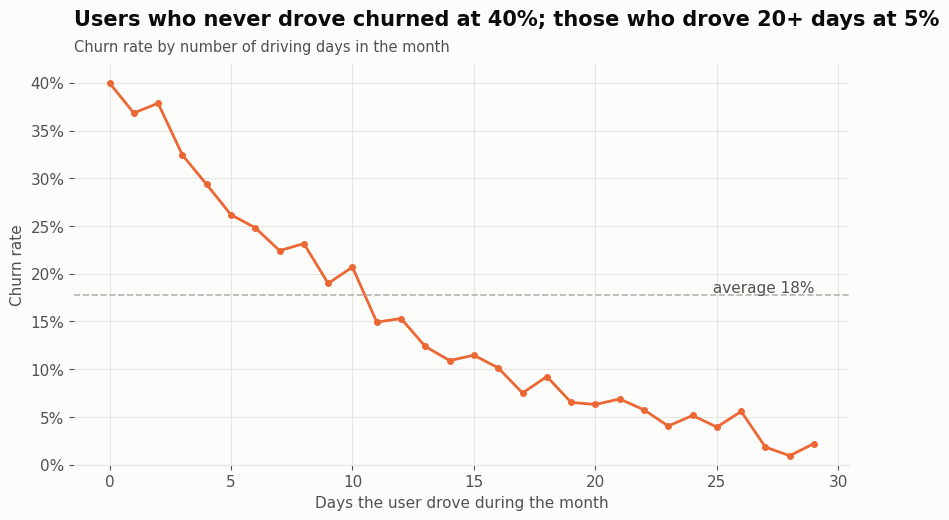

In [34]:
by_days = df.groupby("driving_days")["churned"].agg(churn_rate="mean", users="size")
by_days = by_days[by_days["users"] >= 30]          # hide days with too few users to be reliable

low = df.loc[df["driving_days"] == 0, "churned"].mean()
high = df.loc[df["driving_days"] >= 20, "churned"].mean()

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(by_days.index, by_days["churn_rate"], color=ACCENT, lw=2, marker="o", ms=4)
ax.axhline(BASELINE_CHURN, color=MUTED, lw=1.2, ls="--")
ax.text(by_days.index.max(), BASELINE_CHURN, f" average {BASELINE_CHURN:.0%}", color=INK_2, va="bottom", ha="right")
pct_axis(ax)
ax.set_ylim(0, None)
ax.set_xlabel("Days the user drove during the month")
ax.set_ylabel("Churn rate")
headline(ax, f"Users who never drove churned at {low:.0%}; those who drove 20+ days at {high:.0%}",
         "Churn rate by number of driving days in the month")
save(fig, "01_churn_by_driving_days")
plt.show()

**So what:** driving frequency is the clearest churn signal. The product question becomes *"how do we get users to open Waze on more days?"* (commute alerts, departure-time reminders, saved home/work routes), rather than "how do we win back users who already left?"

### 6.3 H2: Do heavy long-distance drivers churn more?
We look only at users who drove at least once, split into ten equal-size groups by km per driving day.

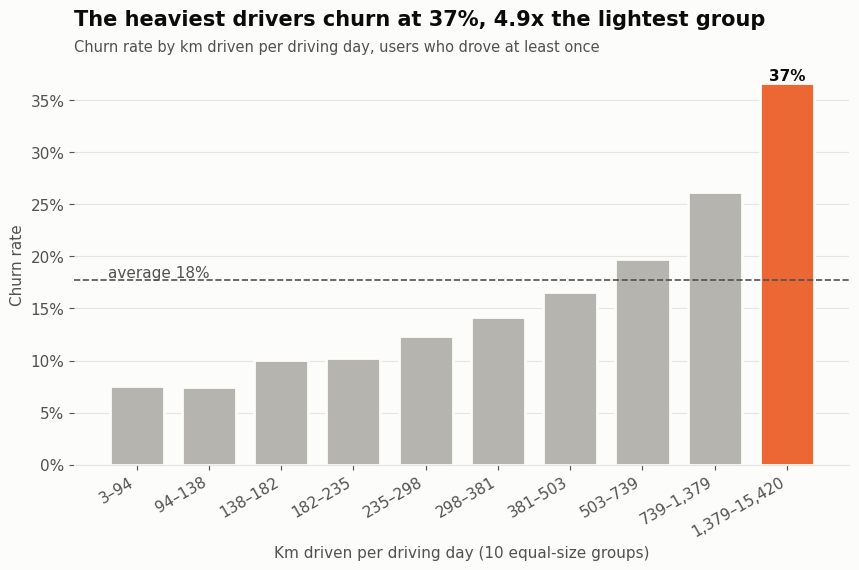

In [35]:
drivers = df[df["driving_days"] > 0].copy()
drivers["km_decile"], edges = pd.qcut(drivers["km_per_driving_day"], 10, retbins=True, labels=False)
by_km = drivers.groupby("km_decile")["churned"].mean()
tick_labels = [f"{edges[i]:,.0f}–{edges[i+1]:,.0f}" for i in range(10)]

fig, ax = plt.subplots(figsize=(10, 5.2))
colors = [MUTED] * 9 + [ACCENT]
ax.bar(range(10), by_km.values, color=colors, width=0.75, edgecolor=SURFACE, linewidth=2)
ax.axhline(BASELINE_CHURN, color=INK_2, lw=1.2, ls="--")
ax.text(-0.4, BASELINE_CHURN, f"average {BASELINE_CHURN:.0%}", color=INK_2, va="bottom")
ax.text(9, by_km.iloc[-1], f"{by_km.iloc[-1]:.0%}", ha="center", va="bottom", color=INK, fontweight="bold")
ax.set_xticks(range(10), tick_labels, rotation=30, ha="right")
ax.grid(axis="x", visible=False)
pct_axis(ax)
ax.set_xlabel("Km driven per driving day (10 equal-size groups)")
ax.set_ylabel("Churn rate")
headline(ax, f"The heaviest drivers churn at {by_km.iloc[-1]:.0%}, {by_km.iloc[-1]/by_km.iloc[0]:.1f}x the lightest group",
         "Churn rate by km driven per driving day, users who drove at least once")
save(fig, "02_churn_by_km_per_day")
plt.show()

**So what:** if the top group stands out, our most intense users may be the least well served: long-haul or professional drivers whose needs (multi-stop routes, truck restrictions, rest stops, fuel prices) Waze may not cover. This is a hypothesis for **user interviews**, not something the data alone can confirm.

### 6.4 H3 and H4: Device and tenure

In [36]:
def chi_square_report(col, name):
    table = pd.crosstab(df[col], df["churned"])
    chi2, p, _, _ = stats.chi2_contingency(table)
    rates = df.groupby(col)["churned"].mean()
    print(f"{name}: churn rate by group -> " + ", ".join(f"{k}: {v:.1%}" for k, v in rates.items()))
    verdict = "no meaningful difference" if p >= 0.05 else "statistically significant difference"
    print(f"  chi-square p-value = {p:.3f} -> {verdict}\n")

chi_square_report("device", "H3 Device")

tenure_bins = [0, 90, 365, 1095, np.inf]
tenure_labels = ["< 3 months", "3–12 months", "1–3 years", "3+ years"]
df["tenure_group"] = pd.cut(df["n_days_after_onboarding"], tenure_bins, labels=tenure_labels, include_lowest=True)
chi_square_report("tenure_group", "H4 Tenure")

H3 Device: churn rate by group -> Android: 17.6%, iPhone: 17.8%
  chi-square p-value = 0.701 -> no meaningful difference

H4 Tenure: churn rate by group -> < 3 months: 26.3%, 3–12 months: 25.8%, 1–3 years: 23.0%, 3+ years: 14.9%
  chi-square p-value = 0.000 -> statistically significant difference



**So what:** a non-significant device result is still useful. It tells the team *not* to spend retention effort on platform-specific fixes. If tenure shows newer users churning more, onboarding becomes a second lever alongside daily-habit building.

## 7. Segmentation: who are we losing?

Models score individuals, but product teams build for **segments**. Rules are applied in order, so each user lands in exactly one segment:

1. **Dormant:** didn't drive at all this month
2. **Professional:** 60+ drives on 15+ days
3. **Occasional long-haul:** drives on fewer than 10 days, but long distances when they do (top 25% km per driving day)
4. **Occasional:** drives on fewer than 10 days, normal distances
5. **Regular:** everyone else (10+ driving days)

The key PM view is the difference between **churn rate** (how risky a segment is) and **share of all churners** (how much of the problem it represents).

In [37]:
KM_HIGH = df.loc[df["driving_days"] > 0, "km_per_driving_day"].quantile(0.75)

def assign_segment(d):
    conditions = [
        d["driving_days"] == 0,
        d["professional_driver"] == 1,
        (d["driving_days"] < 10) & (d["km_per_driving_day"] >= KM_HIGH),
        d["driving_days"] < 10,
    ]
    choices = ["Dormant", "Professional", "Occasional long-haul", "Occasional"]
    return np.select(conditions, choices, default="Regular")

df["segment"] = assign_segment(df)

segments = (df.groupby("segment")
              .agg(users=("churned", "size"), churners=("churned", "sum"), churn_rate=("churned", "mean"))
              .assign(share_of_users=lambda s: s["users"] / s["users"].sum(),
                      share_of_churners=lambda s: s["churners"] / s["churners"].sum())
              .sort_values("churn_rate"))
print(f"'Long-haul' threshold: {KM_HIGH:,.0f} km per driving day")
segments

'Long-haul' threshold: 593 km per driving day


,users,churners,churn_rate,share_of_users,share_of_churners
segment,,,,,
Professional,2488,188,0.076,0.174,0.074
Regular,6070,620,0.102,0.425,0.244
Occasional,1869,426,0.228,0.131,0.168
Occasional long-haul,2889,909,0.315,0.202,0.358
Dormant,983,393,0.400,0.069,0.155


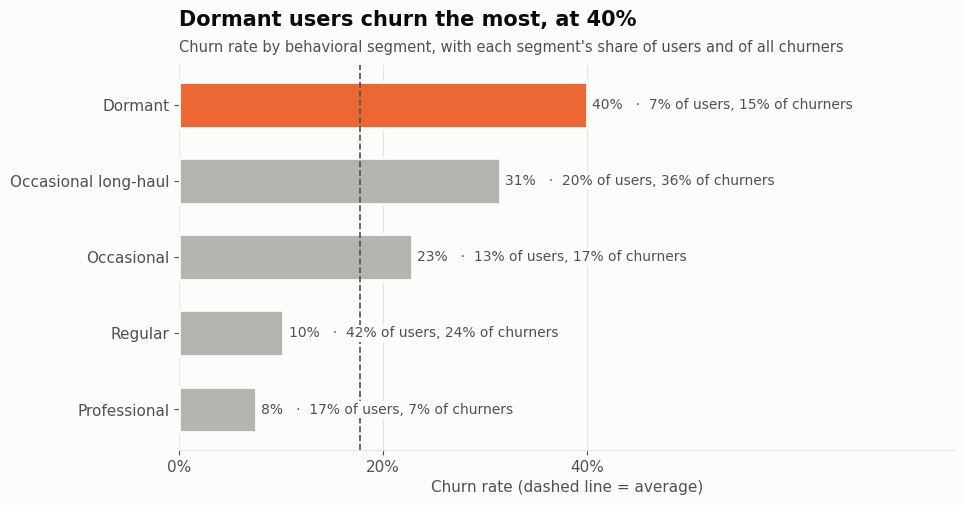

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
top = segments["churn_rate"].idxmax()
colors = [ACCENT if s == top else MUTED for s in segments.index]
ax.barh(segments.index, segments["churn_rate"], color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
ax.axvline(BASELINE_CHURN, color=INK_2, lw=1.2, ls="--")
for i, (seg, row) in enumerate(segments.iterrows()):
    ax.text(row["churn_rate"] + 0.005, i,
            f"{row['churn_rate']:.0%}   ·  {row['share_of_users']:.0%} of users, {row['share_of_churners']:.0%} of churners",
            va="center", color=INK_2, fontsize=10, bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.set_xlim(0, segments["churn_rate"].max() * 1.9)
ax.set_xticks([t for t in np.arange(0, 1.01, 0.2) if t <= segments["churn_rate"].max() + 0.1])
pct_axis(ax, "x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Churn rate (dashed line = average)")
headline(ax, f"{top} users churn the most, at {segments.loc[top, 'churn_rate']:.0%}",
         "Churn rate by behavioral segment, with each segment's share of users and of all churners")
save(fig, "03_churn_by_segment")
plt.show()

**So what:** a segment with a high churn rate but a small share of churners calls for a **targeted** fix; a segment with a moderate rate but a large share of churners is where **volume** is. Section 11 maps one intervention to each.

## 8. Modeling: can we spot churners before they leave?

**Approach**
- **Split:** 60% train, 20% validation (to compare models and pick a threshold), 20% test (touched once, at the end). All splits keep the same churn rate.
- **Candidates:** a simple rule (fewest driving days), logistic regression (interpretable baseline), random forest and XGBoost.
- **How we compare them:** PR-AUC, which measures how well a model ranks churners above retained users and is honest under class imbalance. Accuracy is not used: a model that predicts "nobody churns" would score above 80%.
- **Imbalance:** handled with class weights rather than oversampling, so the data stays real.

The simple rule is there on purpose: **if a model can't clearly beat "flag users who drove the least," the rule is the better thing to ship.**

In [39]:
X, y = df[FEATURES], df["churned"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=RANDOM_STATE)

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} {len(part):>6,} users | churn rate {part.mean():.1%}")

train        8,579 users | churn rate 17.7%
validation   2,860 users | churn rate 17.7%
test         2,860 users | churn rate 17.7%


### 8.1 Logistic regression (interpretable baseline)
Logistic regression struggles when features carry the same information. Check which pairs are highly correlated, then keep one of each.

In [40]:
corr = X_train.drop(columns=BINARY).corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("spearman").reset_index()
             .rename(columns={"level_0": "feature A", "level_1": "feature B"}).query("abs(spearman) > 0.8")
             .sort_values("spearman", key=abs, ascending=False))
pairs

,feature A,feature B,spearman
0,sessions,drives,0.998
92,activity_days,driving_days,0.950
24,drives,km_per_drive,-0.807
10,sessions,km_per_drive,-0.805


In [41]:
# Drop one feature from each near-duplicate pair (keep the one that's easier to explain)
LR_FEATURES = [f for f in FEATURES if f not in {"drives", "activity_days", "duration_minutes_drives"}]
LR_CONTINUOUS = [f for f in LR_FEATURES if f not in BINARY]

class Capper(BaseEstimator, TransformerMixin):
    # Caps each column at a quantile learned on the training data only
    def __init__(self, q=0.95):
        self.q = q
    def fit(self, X, y=None):
        self.caps_ = np.nanquantile(np.asarray(X, dtype=float), self.q, axis=0)
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.caps_)

lr_prep = ColumnTransformer([
    ("continuous", make_pipeline(Capper(0.95), StandardScaler()), LR_CONTINUOUS),
    ("binary", "passthrough", BINARY),
])
logreg = make_pipeline(lr_prep, LogisticRegression(class_weight="balanced", max_iter=2000))
logreg.fit(X_train, y_train)

coefs = pd.DataFrame({
    "feature": [PLAIN[f] for f in LR_CONTINUOUS + BINARY],
    "odds ratio": np.exp(logreg[-1].coef_[0]),
}).sort_values("odds ratio", ascending=False)
coefs["reading"] = np.where(coefs["odds ratio"] > 1, "raises churn odds", "lowers churn odds")
print("Odds ratio per 1 standard deviation (continuous) or yes vs no (binary):")
coefs

Odds ratio per 1 standard deviation (continuous) or yes vs no (binary):


,feature,odds ratio,reading
0,App opens this month,1.206,raises churn odds
3,Trips to top saved place,1.188,raises churn odds
7,Km per driving day,1.084,raises churn odds
8,Km per drive,1.053,raises churn odds
11,Opens per day since joining,1.048,raises churn odds
5,Km driven this month,1.032,raises churn odds
14,iPhone user,1.032,raises churn odds
1,Lifetime app opens,1.025,raises churn odds
4,Trips to 2nd saved place,1.022,raises churn odds
10,Share of lifetime opens this month,0.996,lowers churn odds


### 8.2 Random forest and XGBoost
Tuned with 4-fold cross-validation on the training set, optimizing PR-AUC. Grids are kept small on purpose: on a dataset this size, more tuning mostly overfits.

In [42]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    {"max_depth": [None, 8], "min_samples_leaf": [5, 20], "max_features": ["sqrt", 0.5]},
    scoring="average_precision", cv=cv, n_jobs=-1,
).fit(X_train, y_train)
print("Random forest best params:", rf_search.best_params_, f"| CV PR-AUC {rf_search.best_score_:.3f}")

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_search = GridSearchCV(
    XGBClassifier(objective="binary:logistic", eval_metric="aucpr", scale_pos_weight=pos_weight,
                  subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_depth": [3, 5], "learning_rate": [0.03, 0.1], "n_estimators": [200, 400], "min_child_weight": [1, 5]},
    scoring="average_precision", cv=cv, n_jobs=-1,
).fit(X_train, y_train)
print("XGBoost best params:      ", xgb_search.best_params_, f"| CV PR-AUC {xgb_search.best_score_:.3f}")

Random forest best params: {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 20} | CV PR-AUC 0.391
XGBoost best params:       {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200} | CV PR-AUC 0.387


### 8.3 Model comparison on the validation set
For a fair, decision-focused comparison, each model's threshold is set so it catches **the target share of churners**. Then we ask: how many users does each one have to flag to get there?

In [43]:
models = {
    "Logistic regression": logreg,
    "Random forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}

def churn_scores(name, X_part):
    if name == "Simple rule (fewest driving days)":
        return -X_part["driving_days"].to_numpy(dtype=float)   # fewer driving days = higher risk
    return models[name].predict_proba(X_part)[:, 1]

ALL_MODELS = ["Simple rule (fewest driving days)"] + list(models)

def threshold_for_recall(y_true, score, target):
    # Highest threshold that still catches at least `target` of churners
    _, recall, thresholds = precision_recall_curve(y_true, score)
    return thresholds[np.where(recall[:-1] >= target)[0][-1]]

def evaluate(y_true, score, threshold):
    pred = (score >= threshold).astype(int)
    return {"recall": recall_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "users flagged": pred.mean()}

rows, val_thresholds = [], {}
for name in ALL_MODELS:
    s = churn_scores(name, X_val)
    t = threshold_for_recall(y_val, s, TARGET_RECALL)
    val_thresholds[name] = t
    rows.append({"model": name, "PR-AUC": average_precision_score(y_val, s), "ROC-AUC": roc_auc_score(y_val, s),
                 **evaluate(y_val, s, t)})

comparison = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC", ascending=False)
BEST = comparison.drop(index="Simple rule (fewest driving days)")["PR-AUC"].idxmax()
print(f"Each model's threshold is set to catch ≥{TARGET_RECALL:.0%} of churners. Random guessing PR-AUC = {y_val.mean():.3f}")
print(f"Best model: {BEST}")
comparison

Each model's threshold is set to catch ≥70% of churners. Random guessing PR-AUC = 0.177
Best model: XGBoost


,PR-AUC,ROC-AUC,recall,precision,users flagged
model,,,,,
XGBoost,0.378,0.736,0.700,0.306,0.406
Random forest,0.370,0.730,0.700,0.305,0.407
Logistic regression,0.361,0.738,0.700,0.300,0.414
Simple rule (fewest driving days),0.316,0.718,0.720,0.283,0.451


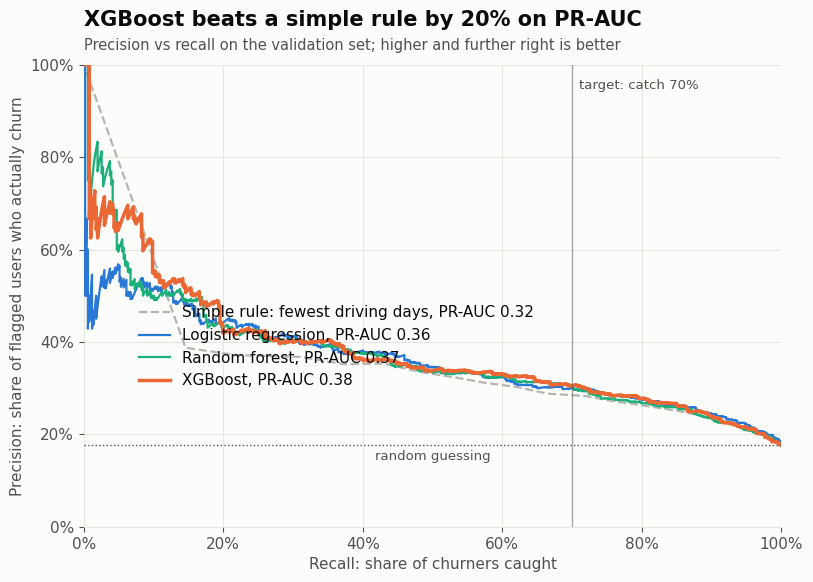

In [44]:
fig, ax = plt.subplots(figsize=(9, 6))
styles = {"Simple rule (fewest driving days)": dict(color=MUTED, ls="--"),
          "Logistic regression": dict(color=BLUE), "Random forest": dict(color=AQUA), "XGBoost": dict(color=ACCENT)}
for name in ALL_MODELS:
    prec, rec, _ = precision_recall_curve(y_val, churn_scores(name, X_val))
    ax.plot(rec, prec, lw=2.5 if name == BEST else 1.6, label=f"{name.replace(' (fewest driving days)', ': fewest driving days')}, PR-AUC {comparison.loc[name, 'PR-AUC']:.2f}",
            **styles[name])
ax.axhline(y_val.mean(), color=INK_2, lw=1, ls=":")
ax.text(0.5, y_val.mean() - 0.01, "random guessing", ha="center", va="top", color=INK_2, fontsize=9.5)
ax.axvline(TARGET_RECALL, color=INK_2, lw=1, alpha=0.5)
ax.text(TARGET_RECALL + 0.01, 0.97, f"target: catch {TARGET_RECALL:.0%}", color=INK_2, fontsize=9.5, va="top")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
pct_axis(ax); pct_axis(ax, "x")
ax.set_xlabel("Recall: share of churners caught")
ax.set_ylabel("Precision: share of flagged users who actually churn")
ax.legend(loc="lower left", bbox_to_anchor=(0.06, 0.27))
lift = comparison.loc[BEST, "PR-AUC"] / comparison.loc["Simple rule (fewest driving days)", "PR-AUC"] - 1
title = (f"{BEST} beats a simple rule by {lift:.0%} on PR-AUC" if lift >= 0.10 else
         f"{BEST} is only {lift:.0%} better than a simple rule" if lift > 0 else
         "A simple rule does as well as the models")
headline(ax, title,
         "Precision vs recall on the validation set; higher and further right is better")
save(fig, "04_model_comparison")
plt.show()

**So what:** look at the gap between the best model and the simple rule. A large gap justifies the cost of running a model in production. A small one means the rule should ship first, with the model as a later improvement. Either answer is a good outcome; pretending the model is better than it is would not be.

## 9. Choosing the threshold: what does catching more churners cost?

The model gives each user a churn score; the **threshold** decides who gets an intervention. That's a business decision, so we make the economics explicit. The values below are **illustrative assumptions** to show the reasoning; replace them with real figures if you have them.

In [45]:
VALUE_OF_SAVED_USER = 10.00   # value of keeping one user (ad revenue + map data they contribute), illustrative
COST_PER_NUDGE = 0.50         # cost of one intervention (incentive, notification fatigue, ops), illustrative
SAVE_RATE = 0.15              # share of real churners the intervention actually keeps, illustrative

def net_value(y_true, score, threshold):
    pred = score >= threshold
    caught = (pred & (y_true.to_numpy() == 1)).sum()
    return caught * SAVE_RATE * VALUE_OF_SAVED_USER - pred.sum() * COST_PER_NUDGE

best_val = churn_scores(BEST, X_val)

rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    t = threshold_for_recall(y_val, best_val, target)
    m = evaluate(y_val, best_val, t)
    rows.append({"catch this share of churners": f"{target:.0%}", "users nudged": f"{m['users flagged']:.0%}",
                 "precision": m["precision"], "nudges per churner caught": 1 / m["precision"],
                 "net value per 1,000 users ($)": net_value(y_val, best_val, t) / len(y_val) * 1000})
tradeoff = pd.DataFrame(rows).set_index("catch this share of churners")
tradeoff

,users nudged,precision,nudges per churner caught,"net value per 1,000 users ($)"
catch this share of churners,,,,
50%,26%,0.338,2.957,1.923
60%,32%,0.329,3.036,-1.923
70%,41%,0.306,3.273,-16.958
80%,51%,0.278,3.596,-42.308
90%,67%,0.238,4.206,-96.329


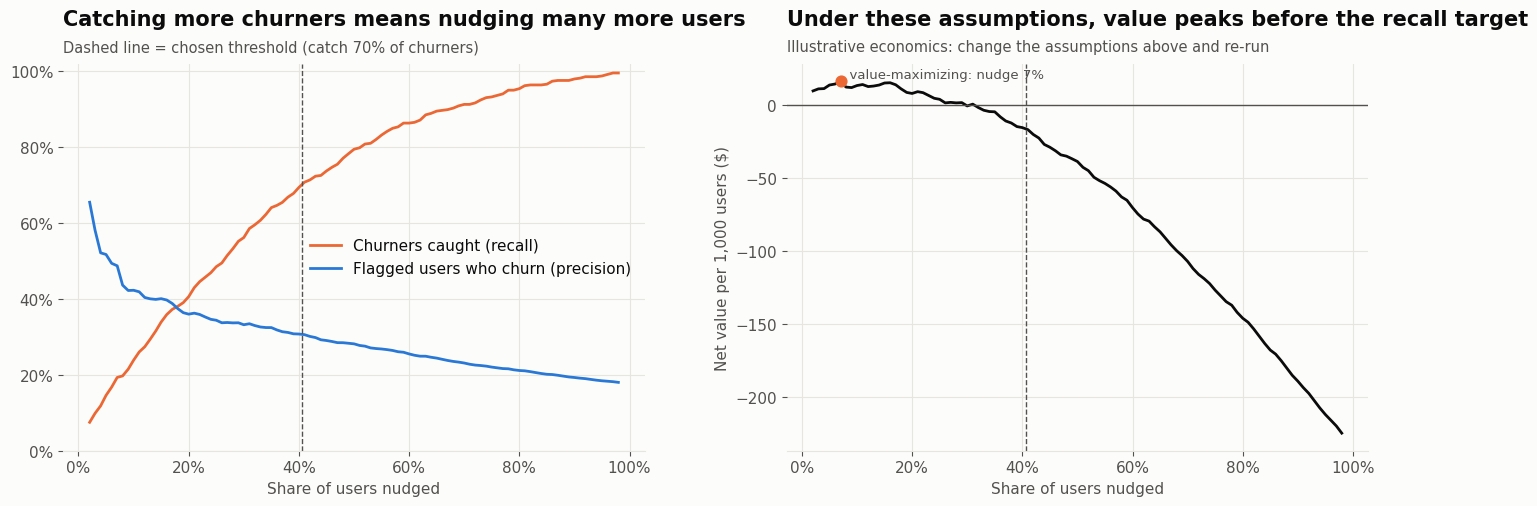

Recall-target threshold: net $-17 per 1,000 users | value-maximizing threshold: net $16 per 1,000 users, recall 19%


In [46]:
grid = np.quantile(best_val, np.linspace(0.02, 0.98, 97))
curve = pd.DataFrame([{"threshold": t, **evaluate(y_val, best_val, t),
                       "net": net_value(y_val, best_val, t) / len(y_val) * 1000} for t in grid])
chosen = val_thresholds[BEST]
value_opt = curve.loc[curve["net"].idxmax()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))
ax1.plot(curve["users flagged"], curve["recall"], color=ACCENT, lw=2, label="Churners caught (recall)")
ax1.plot(curve["users flagged"], curve["precision"], color=BLUE, lw=2, label="Flagged users who churn (precision)")
ax1.axvline(evaluate(y_val, best_val, chosen)["users flagged"], color=INK_2, lw=1, ls="--")
pct_axis(ax1); pct_axis(ax1, "x"); ax1.set_ylim(0, 1.02)
ax1.set_xlabel("Share of users nudged")
ax1.legend(loc="center right")
headline(ax1, "Catching more churners means nudging many more users",
         f"Dashed line = chosen threshold (catch {TARGET_RECALL:.0%} of churners)")

ax2.plot(curve["users flagged"], curve["net"], color=INK, lw=2)
ax2.axhline(0, color=INK_2, lw=1)
ax2.axvline(evaluate(y_val, best_val, chosen)["users flagged"], color=INK_2, lw=1, ls="--")
ax2.scatter([value_opt["users flagged"]], [value_opt["net"]], color=ACCENT, s=60, zorder=3)
ax2.annotate(f"  value-maximizing: nudge {value_opt['users flagged']:.0%}", (value_opt["users flagged"], value_opt["net"]),
             color=INK_2, fontsize=9.5, va="bottom")
pct_axis(ax2, "x")
ax2.set_xlabel("Share of users nudged")
ax2.set_ylabel("Net value per 1,000 users ($)")
peak_note = ("value peaks before the recall target" if value_opt["recall"] < TARGET_RECALL - 0.02 else
             "value peaks after the recall target" if value_opt["recall"] > TARGET_RECALL + 0.02 else
             "the recall target is close to the value peak")
headline(ax2, f"Under these assumptions, {peak_note}",
         "Illustrative economics: change the assumptions above and re-run")
fig.tight_layout(w_pad=4)
save(fig, "05_threshold_tradeoff")
plt.show()

chosen_net = net_value(y_val, best_val, chosen) / len(y_val) * 1000
print(f"Recall-target threshold: net ${chosen_net:,.0f} per 1,000 users | "
      f"value-maximizing threshold: net ${value_opt['net']:,.0f} per 1,000 users, recall {value_opt['recall']:.0%}")

**Decision:** we keep the recall target, because the brief says missing churners is the bigger risk and the lifetime value of a user (and their traffic data) is hard to price. The chart makes the cost of that choice visible, so it's a decision stakeholders can debate rather than a hidden default. If net value at the recall target turns negative, that is a signal to make the intervention cheaper (for example, an in-app prompt instead of an incentive) rather than to give up on recall.

## 10. Final check on unseen data, and what drives churn

### 10.1 Test-set performance (the only time the test set is used)

In [47]:
best_model = models[BEST]
test_scores = churn_scores(BEST, X_test)
test_pred = (test_scores >= chosen).astype(int)
test_metrics = evaluate(y_test, test_scores, chosen)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

print(f"Model: {BEST} | threshold chosen on validation set: {chosen:.3f}\n")
print(f"Out of every 100 churners, we catch {100 * test_metrics['recall']:.0f}.")
print(f"For every churner we catch, we also nudge {fp / tp:.1f} users who would have stayed.")
print(f"We nudge {test_metrics['users flagged']:.0%} of all users. PR-AUC on test: {average_precision_score(y_test, test_scores):.3f}\n")

cm = pd.DataFrame([[tn, fp], [fn, tp]],
                  index=["Actually retained", "Actually churned"],
                  columns=["Not flagged", "Flagged for nudge"])
cm

Model: XGBoost | threshold chosen on validation set: 0.485

Out of every 100 churners, we catch 72.
For every churner we catch, we also nudge 2.1 users who would have stayed.
We nudge 39% of all users. PR-AUC on test: 0.400



,Not flagged,Flagged for nudge
Actually retained,1601,752
Actually churned,144,363


### 10.2 What drives the model's predictions?
Permutation importance shuffles one feature at a time and measures how much worse the model gets. It works for any model and is computed on the test set, so it reflects real predictive value rather than what the model memorized.

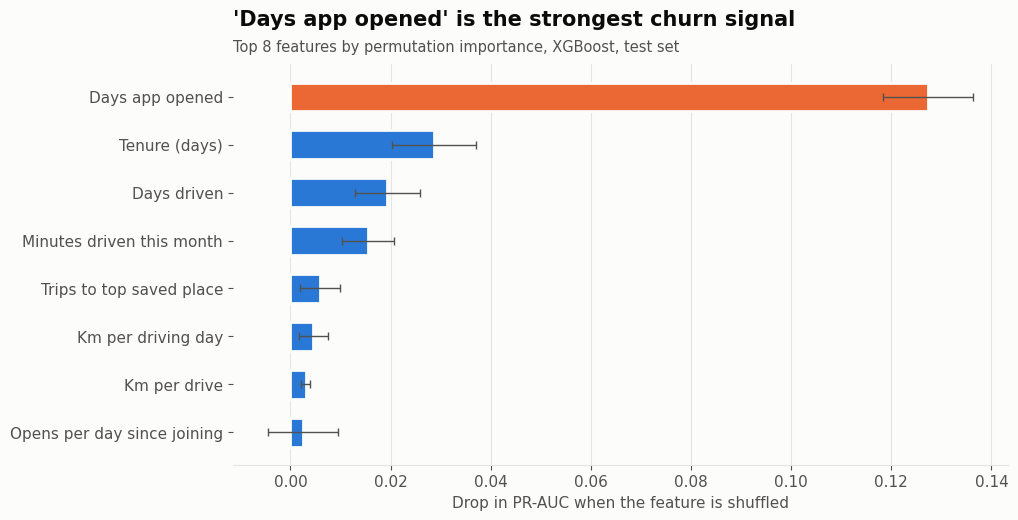

,feature,importance,direction,strength
0,Days app opened,0.127,lower in churners,medium
1,Tenure (days),0.029,lower in churners,small
2,Days driven,0.019,lower in churners,medium
3,Minutes driven this month,0.015,higher in churners,negligible
4,Trips to top saved place,0.006,higher in churners,negligible
5,Km per driving day,0.005,higher in churners,small
6,Km per drive,0.003,lower in churners,negligible
7,Opens per day since joining,0.002,higher in churners,small


In [48]:
imp = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": FEATURES, "importance": imp.importances_mean, "std": imp.importances_std})
                .sort_values("importance", ascending=False).head(8).iloc[::-1])
importance["label"] = importance["feature"].map(PLAIN)

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(importance["label"], importance["importance"], xerr=importance["std"], color=BLUE, height=0.6,
        edgecolor=SURFACE, linewidth=2, error_kw=dict(ecolor=INK_2, lw=1, capsize=3))
ax.barh(importance["label"].iloc[-1], importance["importance"].iloc[-1], color=ACCENT, height=0.6,
        edgecolor=SURFACE, linewidth=2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
headline(ax, f"'{importance['label'].iloc[-1]}' is the strongest churn signal",
         f"Top 8 features by permutation importance, {BEST}, test set")
save(fig, "06_churn_drivers")
plt.show()

drivers_table = importance.iloc[::-1][["feature", "label", "importance"]].merge(
    scorecard[["feature", "direction", "strength"]], left_on="label", right_on="feature", how="left", suffixes=("", "_sc"))
drivers_table["direction"] = drivers_table["direction"].fillna("yes/no flag: see Sections 6.4 and 7")
drivers_table[["label", "importance", "direction", "strength"]].rename(columns={"label": "feature"})

**So what:** importance tells us what the model *uses*, and the direction column tells us *how* it relates to churn. Neither proves cause. "Fewer driving days" might be a symptom of churn rather than a cause, which is exactly why the next section proposes experiments instead of assuming the fix.

## 11. Recommendations and experiment plan

Each recommendation links a finding to an intervention and a way to measure it. Check the segment table and charts above before presenting; adjust the wording if your results differ.

| Segment / finding | Hypothesis | Intervention | Primary metric |
|---|---|---|---|
| **Occasional / Dormant** (few driving days, H1) | Waze isn't part of their routine | Prompt to save Home/Work, then a "time to leave" commute notification | Driving days per user, 30-day retention |
| **Occasional long-haul** (high km per driving day, H2) | They use Waze only for long trips and forget it in between | Trip-planning features (planned drives, stops along the route), post-trip "save this destination" | Retention of this segment |
| **Professional** drivers (lowest churn, 7.6%) | Waze already fits their daily routine | No retention spend; study what keeps them and apply it to long-haul users | Segment retention (guardrail) |
| **Everyone the model flags** | A timely nudge prevents some churn | Weekly risk score; top-risk users get a personalized in-app prompt | Churn rate among flagged users vs a holdout |

**Guardrail metrics** for every test: notification opt-out rate, uninstall rate, and sessions among users who were *not* targeted.

### 11.1 How big does the experiment need to be?
Flagged users churn at roughly the model's precision. We size an A/B test to detect a meaningful relative drop in that rate.

In [49]:
MDE_RELATIVE = 0.10        # smallest improvement worth detecting: 10% relative drop in churn among flagged users

flagged_churn = test_metrics["precision"]
target_churn = flagged_churn * (1 - MDE_RELATIVE)
effect = proportion_effectsize(flagged_churn, target_churn)
n_per_arm = NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1, alternative="two-sided")

print(f"Churn among flagged users today: {flagged_churn:.1%} -> goal: {target_churn:.1%}")
print(f"Needed: {np.ceil(n_per_arm):,.0f} flagged users per arm (95% confidence, 80% power)")
print(f"At {test_metrics['users flagged']:.0%} of users flagged, that means scoring about "
      f"{np.ceil(2 * n_per_arm / test_metrics['users flagged']):,.0f} users in total.")

Churn among flagged users today: 32.6% -> goal: 29.3%
Needed: 3,162 flagged users per arm (95% confidence, 80% power)
At 39% of users flagged, that means scoring about 16,222 users in total.


## 12. Limitations and what I'd ask for next

**What this analysis can't tell us**
- **One month, one snapshot.** We see totals, not trends. A user whose activity is *falling* week over week is likely more at risk than one with steady low use, but this data can't show that.
- **Correlation, not cause.** "Few driving days" might be an early symptom of churn rather than a cause. Only experiments can show whether raising driving days actually keeps people.
- **Modest signal.** With aggregate usage alone, any model will miss a real share of churners or flag many loyal users. That's a property of the data, not something more tuning will fix.
- **Data quality.** Some values look implausible (Section 4.2) and some labels are missing. Both should be raised with the data-engineering team.
- **Illustrative economics.** The dollar values in Section 9 are placeholders to show the reasoning.

**Data I'd request to improve the model**
1. Weekly or daily activity, to capture trends and recency
2. Trip purpose signals (commute vs leisure, time of day, weekday vs weekend)
3. In-app feedback, ratings and support tickets
4. Notification settings and response history
5. Exit survey responses from users who churn

## 13. Results at a glance

Copy the output below into the TL;DR at the top of the notebook and use it for your write-up.

In [50]:
top_seg = segments["churn_rate"].idxmax()
vol_seg = segments["share_of_churners"].idxmax()
rule_pr = comparison.loc["Simple rule (fewest driving days)", "PR-AUC"]

summary = [
    f"Dataset: {len(df):,} labeled Waze users, {BASELINE_CHURN:.1%} churned in the month.",
    f"Strongest signal: driving frequency. Users who never drove churned at {low:.0%}, vs {high:.0%} for users who drove 20+ days.",
    f"Heaviest drivers (top 10% by km per driving day) churned at {by_km.iloc[-1]:.0%}, "
    f"{by_km.iloc[-1] / BASELINE_CHURN:.1f}x the average.",
    f"Riskiest segment: {top_seg} ({segments.loc[top_seg, 'churn_rate']:.0%} churn). "
    f"Largest share of churners: {vol_seg} ({segments.loc[vol_seg, 'share_of_churners']:.0%} of all churners).",
    f"Best model: {BEST}, PR-AUC {comparison.loc[BEST, 'PR-AUC']:.2f} vs {rule_pr:.2f} for a simple rule "
    f"and {y_val.mean():.2f} for random guessing.",
    f"On unseen users it catches {test_metrics['recall']:.0%} of churners by nudging {test_metrics['users flagged']:.0%} of users "
    f"({fp / tp:.1f} unneeded nudges per churner caught).",
    f"An A/B test needs about {np.ceil(n_per_arm):,.0f} flagged users per arm to detect a {MDE_RELATIVE:.0%} relative drop in churn.",
]
print("\n".join(f"• {line}" for line in summary))
print(f"\nCharts for the post are saved in ./{CHART_DIR}/")

• Dataset: 14,299 labeled Waze users, 17.7% churned in the month.
• Strongest signal: driving frequency. Users who never drove churned at 40%, vs 5% for users who drove 20+ days.
• Heaviest drivers (top 10% by km per driving day) churned at 37%, 2.1x the average.
• Riskiest segment: Dormant (40% churn). Largest share of churners: Occasional long-haul (36% of all churners).
• Best model: XGBoost, PR-AUC 0.38 vs 0.32 for a simple rule and 0.18 for random guessing.
• On unseen users it catches 72% of churners by nudging 39% of users (2.1 unneeded nudges per churner caught).
• An A/B test needs about 3,162 flagged users per arm to detect a 10% relative drop in churn.

Charts for the post are saved in ./charts/
